# Sensibilidad del valor de información al prior
Pregunta: ¿cambia la decisión de pilotear precios cuando conservamos la tasa esperada de conversión y cambiamos la precisión subjetiva del prior? Datos enteramente sintéticos.

## Derivación\nPara $p_j\sim\mathrm{Beta}(\alpha_j,\beta_j)$, $m_j=\alpha_j/(\alpha_j+\beta_j)$ y $\kappa_j=\alpha_j+\beta_j$. Escalar $\kappa_j$ por $c>0$ conservando $m_j$ da $\alpha'_j=c m_j\kappa_j=c\alpha_j$, $\beta'_j=c(1-m_j)\kappa_j=c\beta_j$. La predictiva sigue siendo Beta-Binomial. Sumamos exactamente sus resultados para calcular $EVSI(c)=\mathbb E_{X_A,X_B}[\max_j V_j(X)]-\max_j V_j(0)$. El costo se resta después; las unidades son contribución abstracta por cliente.

In [1]:
import sys
from pathlib import Path
root=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
sys.path.insert(0,str(root/'src'))
from evsi import Price
from prior_sensitivity import concentration_grid
p=[Price('A',100,11,9),Price('B',180,5,15)]
rows=concentration_grid(p,20,1,[.25,.5,1,2,4,10,100])
assert all(x['baseline_value']==rows[0]['baseline_value'] for x in rows)
[(x['concentration_multiplier'],round(x['evsi'],6),x['decision']) for x in rows]

Out[0]: 
[(0.25, 9.52397, 'pilot'),
 (0.5, 5.245229, 'pilot'),
 (1, 2.21368, 'pilot'),
 (2, 0.54901, 'launch_now_or_close'),
 (4, 0.036297, 'launch_now_or_close'),
 (10, 1e-06, 'launch_now_or_close'),
 (100, -0.0, 'launch_now_or_close')]


## Contraste y límite
El baseline es la decisión inmediata sin piloto sobre los mismos priors. Cambiar solo $c$ identifica sensibilidad de la recomendación al prior, no sensibilidad de ventas reales. Comprobamos monotonicidad únicamente en la grilla predefinida; no es un teorema universal.

Out[0]: <Figure size 600x350 with 1 Axes>


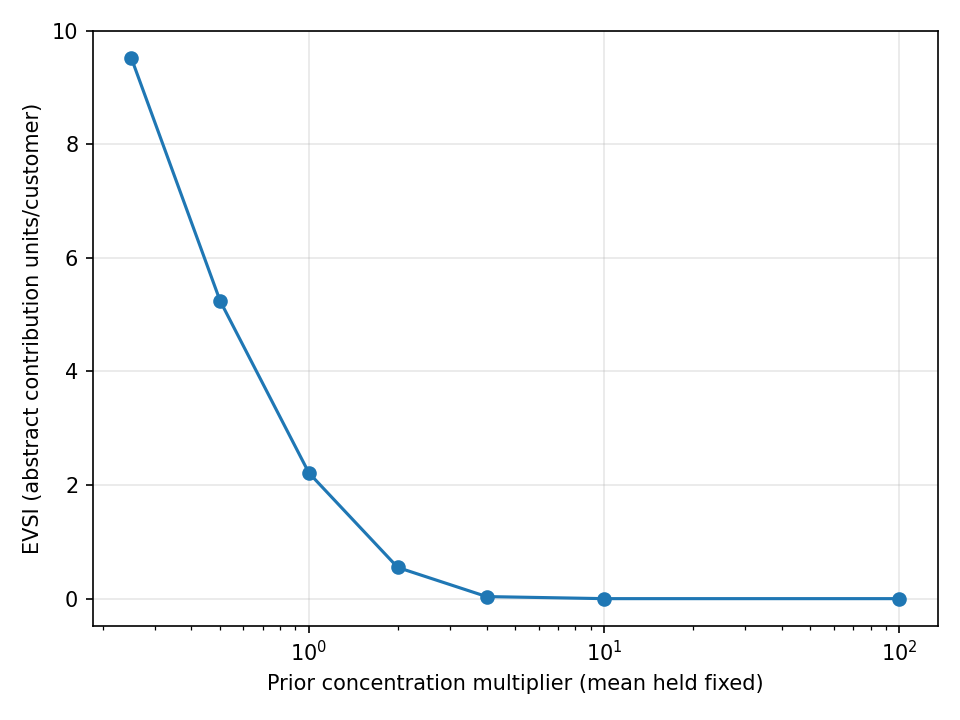

In [2]:
import matplotlib.pyplot as plt
fig, ax=plt.subplots(figsize=(6,3.5))
ax.plot([x['concentration_multiplier'] for x in rows],[x['evsi'] for x in rows],marker='o',label='EVSI exacto')
ax.axhline(1,color='gray',linestyle='--',label='Costo de piloto')
ax.set_xscale('log'); ax.set_xlabel('Multiplicador de concentración del prior'); ax.set_ylabel('Contribución abstracta por cliente'); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout()
fig

## Resultado calculado
La herramienta muestra en qué regímenes la decisión simulada cambia. La prueba de decisión y costos está en `tests/test_prior_sensitivity.py`. No se infiere causalidad ni se recomienda un precio para clientes reales.